In [1]:
import pandas as pd
import seaborn as sns
import string
import re
import nltk
import matplotlib.pyplot as plt

In [2]:
import warnings
warnings.filterwarnings('ignore')

### EDA

In [3]:
df = pd.read_excel('dataset-Copy1.xlsx', sheet_name='Sheet1')
df

,title,rating,body
0,Horrible product,1,Very disappointed with the overall performance...
1,Camera quality is not like 48 megapixel,3,Camera quality is low
2,Overall,4,"Got the mobile on the launch date,Battery must..."
3,A big no from me,1,1. It doesn't work with 5.0GHz WiFi frequency....
4,Put your money somewhere else,1,"Not worth buying....faulty software, poor disp..."
...,...,...,...
1435,Excellent mobile,5,Excellent mobile
1436,Never expected from samsung,1,"All over mobile performance is very poor, neve..."
1437,Good value for money,5,Battery life is good but camera clarity could ...
1438,Unreal and whitish display,1,"It's a very bad product, highly dissatisfied....."


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1440 entries, 0 to 1439
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   title   1440 non-null   object
 1   rating  1440 non-null   int64 
 2   body    1440 non-null   object
dtypes: int64(1), object(2)
memory usage: 33.9+ KB


In [5]:
df['body'].loc[0]

'Very disappointed with the overall performance from Samsung'

In [6]:
df['body']

0       Very disappointed with the overall performance...
1                                   Camera quality is low
2       Got the mobile on the launch date,Battery must...
3       1. It doesn't work with 5.0GHz WiFi frequency....
4       Not worth buying....faulty software, poor disp...
                              ...                        
1435                                     Excellent mobile
1436    All over mobile performance is very poor, neve...
1437    Battery life is good but camera clarity could ...
1438    It's a very bad product, highly dissatisfied.....
1439    The phone is a real beast the battery lasts ea...
Name: body, Length: 1440, dtype: object

In [7]:
# Rating Distribution

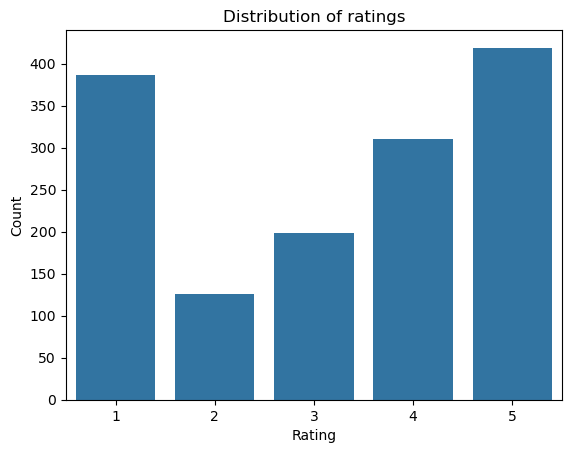

In [8]:
sns.countplot(data=df, x='rating')
plt.title('Distribution of ratings')
plt.xlabel('Rating')
plt.ylabel('Count')
plt.show()

In [9]:
# word count Distribution

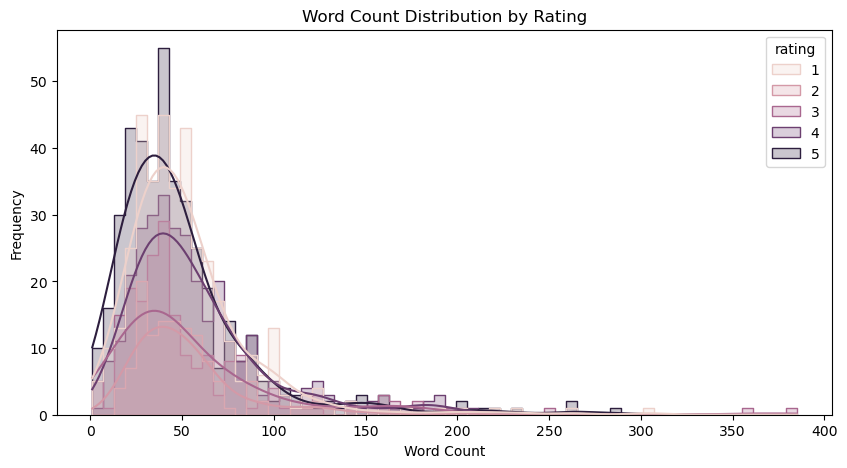

In [10]:
# Create new columns for lengths
df['body_len'] = df['body'].apply(len)
df['word_count'] = df['body'].apply(lambda x: len(str(x).split()))

# Histogram of text length by rating
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='word_count', hue='rating', kde=True, element='step')
plt.title('Word Count Distribution by Rating')
plt.xlabel('Word Count')
plt.ylabel('Frequency')
plt.show()

In [11]:
# Word count VS Rating 

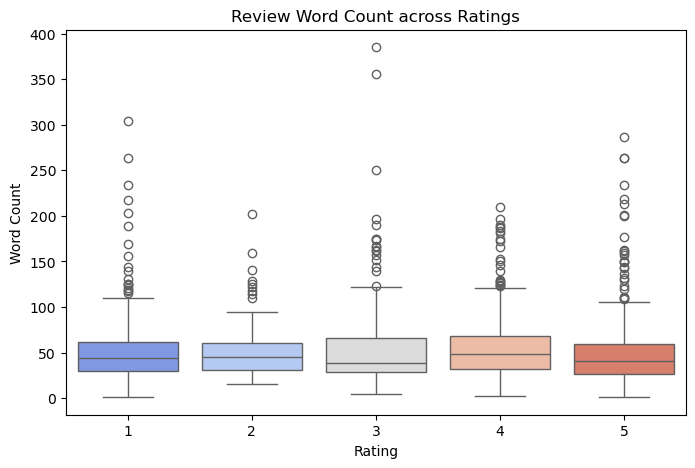

In [12]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='rating', y='word_count', palette='coolwarm')
plt.title('Review Word Count across Ratings')
plt.xlabel('Rating')
plt.ylabel('Word Count')
plt.show()

#### a.Convert to lowercase

In [13]:
df['clean_body'] = df['body'].str.lower()
df['clean_body']

0       very disappointed with the overall performance...
1                                   camera quality is low
2       got the mobile on the launch date,battery must...
3       1. it doesn't work with 5.0ghz wifi frequency....
4       not worth buying....faulty software, poor disp...
                              ...                        
1435                                     excellent mobile
1436    all over mobile performance is very poor, neve...
1437    battery life is good but camera clarity could ...
1438    it's a very bad product, highly dissatisfied.....
1439    the phone is a real beast the battery lasts ea...
Name: clean_body, Length: 1440, dtype: object

#### b.Remove stopwords

In [14]:
from nltk.corpus import stopwords
stop_words = set(stopwords.words('english'))

def remove_stopword(x):
    lst = nltk.word_tokenize(x)
    new_lst = [x for x in lst if x not in stop_words]
    return ' '.join(new_lst)

In [15]:
df['clean_body'] = df['clean_body'].apply(remove_stopword)
df['clean_body']

0                disappointed overall performance samsung
1                                      camera quality low
2       got mobile launch date , battery must apprecia...
3       1. n't work 5.0ghz wifi frequency . 2.4ghz old...
4       worth buying .... faulty software , poor displ...
                              ...                        
1435                                     excellent mobile
1436    mobile performance poor , never buy one produc...
1437    battery life good camera clarity could little ...
1438    's bad product , highly dissatisfied .. specif...
1439    phone real beast battery lasts easily 1 day co...
Name: clean_body, Length: 1440, dtype: object

#### c.Remove special characters

In [16]:
def clean_text(text):
    text = re.sub(r'[^\w\s]', '', text)
    return text

In [17]:
df['clean_body'] = df['clean_body'].apply(clean_text)
df['clean_body']

0                disappointed overall performance samsung
1                                      camera quality low
2       got mobile launch date  battery must appreciat...
3       1 nt work 50ghz wifi frequency  24ghz old scho...
4       worth buying  faulty software  poor display qu...
                              ...                        
1435                                     excellent mobile
1436    mobile performance poor  never buy one product...
1437    battery life good camera clarity could little ...
1438    s bad product  highly dissatisfied  specifical...
1439    phone real beast battery lasts easily 1 day co...
Name: clean_body, Length: 1440, dtype: object

#### d.Lemmatize the text

In [18]:
from nltk.stem import WordNetLemmatizer

In [19]:
lem = WordNetLemmatizer()

In [20]:
def lemmatize(x):
    lem_lst = []
    lst = x.split()
    for word in lst:
        lem_lst.append(lem.lemmatize(word, 'v'))
    return ' '.join(lem_lst)

In [21]:
df['clean_body'] = df['clean_body'].apply(lemmatize)
df['clean_body']

0                  disappoint overall performance samsung
1                                      camera quality low
2       get mobile launch date battery must appreciate...
3       1 nt work 50ghz wifi frequency 24ghz old schoo...
4       worth buy faulty software poor display quality...
                              ...                        
1435                                     excellent mobile
1436    mobile performance poor never buy one product ...
1437    battery life good camera clarity could little ...
1438    s bad product highly dissatisfy specifically c...
1439    phone real beast battery last easily 1 day con...
Name: clean_body, Length: 1440, dtype: object

#### Wordcloud

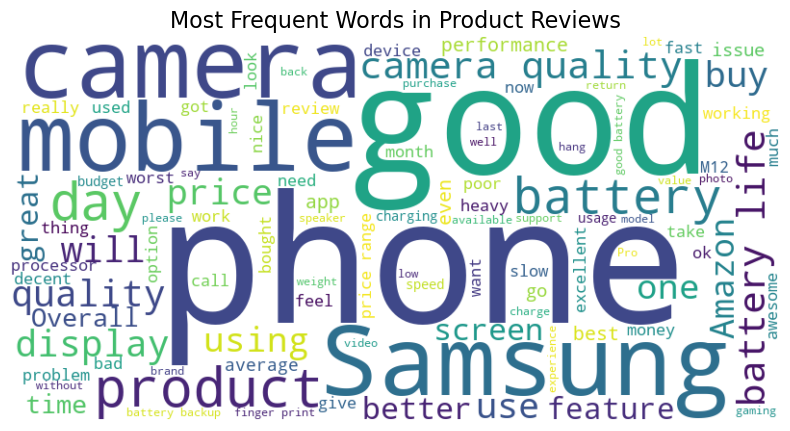

In [22]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# 1. Combine all cleaned and lemmatized reviews into a single text string
all_words = ' '.join(df['body'].dropna())

# 2. Generate the WordCloud
wordcloud = WordCloud(
    width=800, 
    height=400, 
    background_color='white',
    max_words=100
).generate(all_words)

# 3. Display the WordCloud plot
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')  # Hide axis ticks
plt.title('Most Frequent Words in Product Reviews', fontsize=16)
plt.show()

### Sentiment Analysis

#### a.Vader

In [23]:
from nltk.sentiment.vader import SentimentIntensityAnalyzer

In [24]:
nltk.download('vader_lexicon')

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\Shantilal\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


True

In [25]:
sia = SentimentIntensityAnalyzer()
df['vader_score'] = df['body'].apply(lambda x: sia.polarity_scores(str(x))['compound'])

In [26]:
df['vader_score']

0      -0.5256
1      -0.2732
2       0.1027
3      -0.8923
4      -0.8033
         ...  
1435    0.5719
1436   -0.9038
1437    0.9075
1438   -0.5863
1439    0.9109
Name: vader_score, Length: 1440, dtype: float64

In [27]:
def get_vader_sentiment(score):
    if score >= 0.05:
        return 'Positive'
    elif score <=-0.05:
        return 'Negative'
    else:
        return 'Neutral'

In [28]:
df['vader_sentiment'] = df['vader_score'].apply(get_vader_sentiment)

In [29]:
df['vader_sentiment']

0       Negative
1       Negative
2       Positive
3       Negative
4       Negative
          ...   
1435    Positive
1436    Negative
1437    Positive
1438    Negative
1439    Positive
Name: vader_sentiment, Length: 1440, dtype: object

#### b.Textblob

In [30]:
#!pip install textblob
from textblob import TextBlob

In [31]:
df['textblob_score'] = df['body'].apply(lambda x: TextBlob(str(x)).sentiment.polarity)

In [32]:
df['textblob_score']

0      -0.487500
1       0.000000
2       0.025000
3      -0.005606
4       0.029762
          ...   
1435    1.000000
1436   -0.560000
1437    0.336458
1438   -0.305556
1439    0.305000
Name: textblob_score, Length: 1440, dtype: float64

In [33]:
def get_textblob_sentiment(score):
    if score > 0:
        return 'Positive'
    elif score < 0:
        return 'Negative'
    else:
        return 'Neutral'

In [34]:
df['textblob_sentiment'] = df['textblob_score'].apply(get_textblob_sentiment)

In [35]:
df['textblob_sentiment']

0       Negative
1        Neutral
2       Positive
3       Negative
4       Positive
          ...   
1435    Positive
1436    Negative
1437    Positive
1438    Negative
1439    Positive
Name: textblob_sentiment, Length: 1440, dtype: object

In [36]:
df[['body', 'vader_score', 'vader_sentiment', 'textblob_score', 'textblob_sentiment']].head(10)

,body,vader_score,vader_sentiment,textblob_score,textblob_sentiment
0,Very disappointed with the overall performance...,-0.5256,Negative,-0.487500,Negative
1,Camera quality is low,-0.2732,Negative,0.000000,Neutral
2,"Got the mobile on the launch date,Battery must...",0.1027,Positive,0.025000,Positive
3,1. It doesn't work with 5.0GHz WiFi frequency....,-0.8923,Negative,-0.005606,Negative
4,"Not worth buying....faulty software, poor disp...",-0.8033,Negative,0.029762,Positive
5,I will never purchase Samsung phones. Phone is...,-0.6486,Negative,-0.147917,Negative
6,This is worst samsung mobile I have seen from ...,-0.4215,Negative,-0.450000,Negative
7,मोबाइल का कैमरा बिल्कुल भी सही नही है 48 PM बत...,0.0000,Neutral,0.000000,Neutral
8,The phone hangs a lot and is very slow. I rece...,0.0000,Neutral,-0.390000,Negative
9,Very poor quality camera .Found box seal damag...,-0.7089,Negative,-0.160000,Negative


In [37]:
from sklearn.preprocessing import LabelEncoder

In [38]:
lenc = LabelEncoder()
df['vader_sentiment'] = lenc.fit_transform(df['vader_sentiment'])
df['vader_sentiment']

0       0
1       0
2       2
3       0
4       0
       ..
1435    2
1436    0
1437    2
1438    0
1439    2
Name: vader_sentiment, Length: 1440, dtype: int64

In [39]:
df['vader_sentiment'].value_counts()

vader_sentiment
2    902
0    451
1     87
Name: count, dtype: int64

In [40]:
X = df['clean_body']
y = df['vader_sentiment']

### Model building and Evaluvation

In [41]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

In [42]:
X_train_raw,X_test_raw,y_train,y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)
X_train_raw.shape,X_test_raw.shape,y_train.shape,y_test.shape

((1152,), (288,), (1152,), (288,))

In [43]:
tfidf = TfidfVectorizer()
X_train = tfidf.fit_transform(X_train_raw)
X_test = tfidf.transform(X_test_raw)

#### 1.Logistic Regression

In [44]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

In [80]:
from sklearn.linear_model import LogisticRegression

model1 = LogisticRegression(
    C=0.05,
    class_weight='balanced',
    max_iter=1000,
    random_state=42
)

model1.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,0.05
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [81]:
yhat_train = model1.predict(X_train)

In [82]:
print(classification_report(y_train,yhat_train))

              precision    recall  f1-score   support

           0       0.74      0.81      0.77       361
           1       0.63      0.94      0.76        69
           2       0.91      0.83      0.87       722

    accuracy                           0.83      1152
   macro avg       0.76      0.86      0.80      1152
weighted avg       0.84      0.83      0.83      1152



In [83]:
yhat_test = model1.predict(X_test)

In [84]:
print(classification_report(y_test,yhat_test))

              precision    recall  f1-score   support

           0       0.56      0.66      0.61        90
           1       0.48      0.56      0.51        18
           2       0.81      0.73      0.77       180

    accuracy                           0.70       288
   macro avg       0.62      0.65      0.63       288
weighted avg       0.71      0.70      0.70       288



#### 2.SVM

In [50]:
from sklearn.svm import LinearSVC

In [51]:
model2 = LinearSVC(random_state=42, class_weight='balanced')
model2.fit(X_train,y_train)

,penalty,'l2'
,loss,'squared_hinge'
,dual,'auto'
,tol,0.0001
,C,1.0
,multi_class,'ovr'
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,verbose,0
,random_state,42


In [52]:
yhat_train = model2.predict(X_train)

In [53]:
print(classification_report(y_train,yhat_train))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       361
           1       1.00      1.00      1.00        69
           2       1.00      1.00      1.00       722

    accuracy                           1.00      1152
   macro avg       1.00      1.00      1.00      1152
weighted avg       1.00      1.00      1.00      1152



In [54]:
yhat_test = model2.predict(X_test)

In [55]:
print(classification_report(y_test,yhat_test))

              precision    recall  f1-score   support

           0       0.64      0.61      0.62        90
           1       0.33      0.17      0.22        18
           2       0.80      0.86      0.83       180

    accuracy                           0.74       288
   macro avg       0.59      0.54      0.56       288
weighted avg       0.72      0.74      0.73       288



#### 3.Decision Tree

In [56]:
from sklearn.tree import DecisionTreeClassifier

In [57]:
model3 = DecisionTreeClassifier(max_depth=8, criterion='gini', max_leaf_nodes=15)
model3.fit(X_train,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,8
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,15
,min_impurity_decrease,0.0
,class_weight,None


In [58]:
yhat_train = model3.predict(X_train)

In [59]:
print(classification_report(y_train,yhat_train))

              precision    recall  f1-score   support

           0       0.80      0.52      0.63       361
           1       0.86      0.09      0.16        69
           2       0.75      0.94      0.83       722

    accuracy                           0.76      1152
   macro avg       0.80      0.52      0.54      1152
weighted avg       0.77      0.76      0.73      1152



In [60]:
yhat_test = model3.predict(X_test)

In [61]:
print(classification_report(y_test,yhat_test))

              precision    recall  f1-score   support

           0       0.64      0.40      0.49        90
           1       0.00      0.00      0.00        18
           2       0.70      0.89      0.78       180

    accuracy                           0.68       288
   macro avg       0.45      0.43      0.43       288
weighted avg       0.64      0.68      0.64       288



#### 4.Random Forest

In [62]:
from sklearn.ensemble import RandomForestClassifier

In [63]:
model4 = RandomForestClassifier(n_estimators=200,max_depth=4,class_weight='balanced')
model4.fit(X_train,y_train)

,n_estimators,200
,criterion,'gini'
,max_depth,4
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [64]:
yhat_train = model4.predict(X_train)

In [65]:
print(classification_report(y_train,yhat_train))

              precision    recall  f1-score   support

           0       0.70      0.81      0.75       361
           1       0.89      0.74      0.81        69
           2       0.90      0.84      0.87       722

    accuracy                           0.82      1152
   macro avg       0.83      0.80      0.81      1152
weighted avg       0.83      0.82      0.83      1152



In [66]:
yhat_test = model4.predict(X_test)

In [67]:
print(classification_report(y_test,yhat_test))

              precision    recall  f1-score   support

           0       0.51      0.62      0.56        90
           1       0.30      0.17      0.21        18
           2       0.79      0.74      0.77       180

    accuracy                           0.67       288
   macro avg       0.54      0.51      0.52       288
weighted avg       0.67      0.67      0.67       288



#### 5.KNN

In [68]:
from sklearn.neighbors import KNeighborsClassifier

In [69]:
model5 = KNeighborsClassifier(n_neighbors=5, weights='distance')
model5.fit(X_train,y_train)

,n_neighbors,5
,weights,'distance'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [70]:
yhat_train = model5.predict(X_train)

In [71]:
print(classification_report(y_train,yhat_train))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       361
           1       1.00      1.00      1.00        69
           2       1.00      1.00      1.00       722

    accuracy                           1.00      1152
   macro avg       1.00      1.00      1.00      1152
weighted avg       1.00      1.00      1.00      1152



In [72]:
yhat_test = model5.predict(X_test)

In [73]:
print(classification_report(y_test,yhat_test))

              precision    recall  f1-score   support

           0       0.55      0.41      0.47        90
           1       0.60      0.17      0.26        18
           2       0.71      0.86      0.78       180

    accuracy                           0.67       288
   macro avg       0.62      0.48      0.50       288
weighted avg       0.66      0.67      0.65       288



### Model deployment

In [74]:
import joblib

In [87]:
#joblib.dump(model1, 'logistic_sentiment_model.pkl')
#joblib.dump(tfidf, 'tfidf_vectorizer.pkl')

In [76]:
#pip install streamlit joblib scikit-learn

In [86]:
!streamlit run app.py

^C
